# Daten vorbereiten

## Aufgabe 2.1: Bereinigung der Daten
### a)
In den Kommentaren der Datei "data_preparation.py" werden die Aufgaben beantwortet.
### b)
In den Kommentaren der Datei "merge_data.py" werden die Aufgaben beantwortet.
### c)
#### Vorgegebene Merkmale
- Das Merkmal "Schlechte Bewertung" wurde in orders eingefügt. Dieses Attribut ist verfügbar, wenn in reviews mindestens eine Bewertung abgegeben worden ist für die Bestellung mit order_id als Schlüssel.
- Die Lieferdauer wurde in orders eingefügt. Sie ist verfügbar, wenn in orders für ein order_id jeweils order_delivered_customer_date und order_purchase_timestamp definiert sind.
- Die Verspätung wurde in orders eingebaut. Die Verspätung ist verfügbar, wenn in orders für ein order_id jeweils order_delivered_customer_date und order_estimated_delivery_date vorhanden sind.
- Das Attribut "Versand zwischen Bundesstaaten" wurde in orders eingefügt. Dieses Attribut ist verfügbar, wenn für eine Bestellung neben der order_id in orders auch seller_id und customer_id definiert sind. Mindestens ein Eintrag mit den relevanten Attributen muss in items sein. Zudem muss die customer_id zu einem Kunden gehören, der in customers gespeichert worden ist. Außerdem muss die seller_id tatsächlich einen Verkäufer in sellers gehören.
- Für den Warenkorb/Fracht wurden 4 Attribute allesamt in orders implementiert. Die Attribute Positionszahl, Warenwert, Frachtkosten sowie Anteil der Frachtkosten an Warentwert plus Frachtkosten sind verfügbar, wenn für eine Bestellung mit der order_id mindestens ein Eintrag in items vorhanden ist mit Positionszahl, Preis sowie Frachtkosten.
#### Eigenes Merkmal: Umsatz (sales_volume)
- Hiermit misst man den Gesamtumsatz pro Verkäufer.
- Wenn mindestens ein Eintrag in items mit Preis sowie Frachtkosten vorhanden ist, dann kann der Umsatz berechnet werden. Es muss auch die seller_id existieren, um den richtigen Händler den Umsatz zuweisen zu können. Zudem muss order_status gleich delivered sein, da die Lieferung dann abgeschlossen ist.

In [13]:
import importlib
from pathlib import Path

import data_preparation
import merge_data
import eda_for_logistics_management
import eda_for_services_management

importlib.reload(data_preparation)
importlib.reload(merge_data)
importlib.reload(eda_for_logistics_management)
importlib.reload(eda_for_services_management)

from data_preparation import convert_data_to_cleaned_version
from merge_data import create_merged_tables

from eda_for_logistics_management import analyze_sales_volume_from_sellers
from eda_for_logistics_management import analyze_sales_volume_per_state
from eda_for_logistics_management import analyze_sales_volume_per_product_id
from eda_for_logistics_management import analyze_sales_volume_per_category
from eda_for_logistics_management import draw_sales_volume_per_month
from eda_for_logistics_management import connection_between_sales_volume_and_number_of_photos

from eda_for_services_management import analyze_review_score
from eda_for_services_management import analyze_bad_reviews
from eda_for_services_management import connection_between_delivery_quality_and_reviews
from eda_for_services_management import connection_betweeen_review_score_and_total_value

convert_data_to_cleaned_version()
create_merged_tables()

C:\Users\Stas Cuprunov\Datenanalyse und Business Intelligence 1\Projekt\data_preparation.py:435: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



# Aufgabe 2.2: Data Stories
## EDA für Serviceleitung

### Wie hat sich die Bewertung im Laufe der Zeit entwickelt?
- Im Jahr 2016 ist der Durchschnitt bei lediglich 3,5. Die Jahre 2017 und 2018 haben einen Durchschnittswert etwas mehr als 4. Das heißt, dass es eine deutliche Steigerung im Vergleich zu 2016 gab.
- Im Jahr 2016 gab es einen raschen Abfall der durchschnittlichen Bewertung. Es waren nur 50 Bewertungen in Dezember 2016. Jedoch waren keine Verspätungen vorhanden.
- Danach hat die durchschnittliche Bewertung sich auf etwa 4 stabilisiert.
- Einen Einknick gab es in Oktober 2018 sowohl bei der durchschnittlichen Bewertung als auch bei der Anzahl der Bewertungen. Die Anzahl an Verspätungen ist gering. Die Vermutung ist, dass noch nicht alle Daten erfasst worden sind.

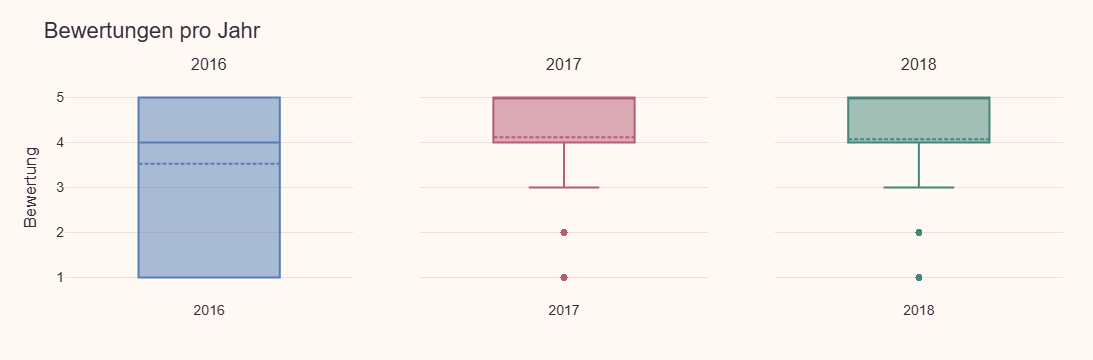

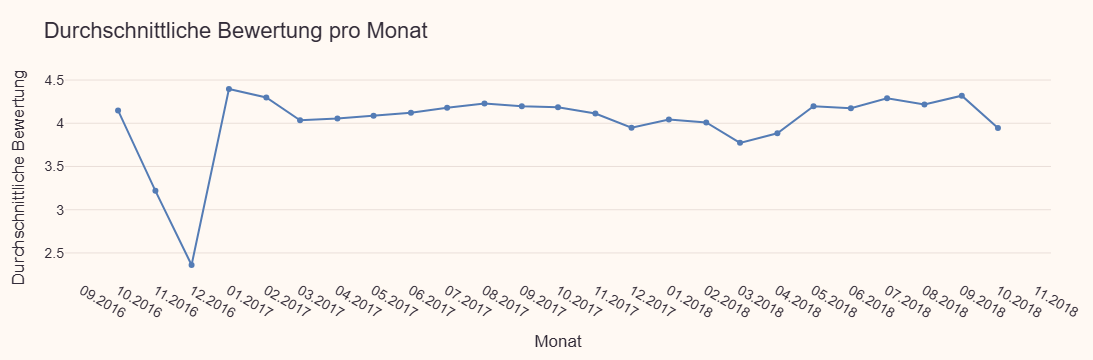

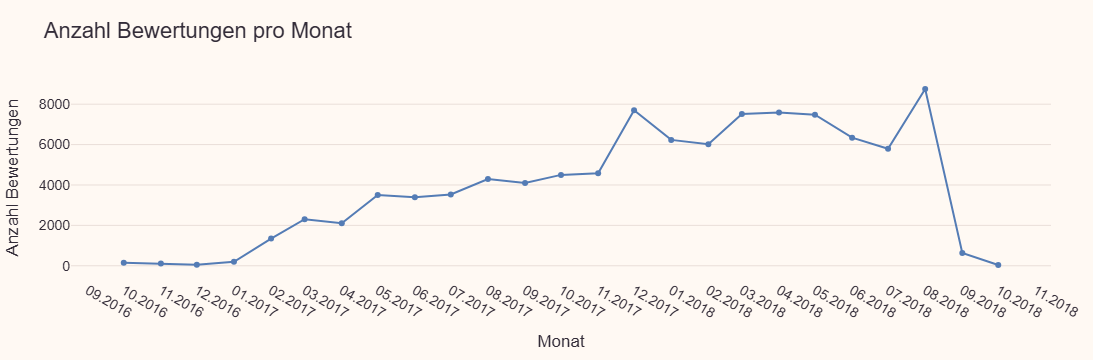

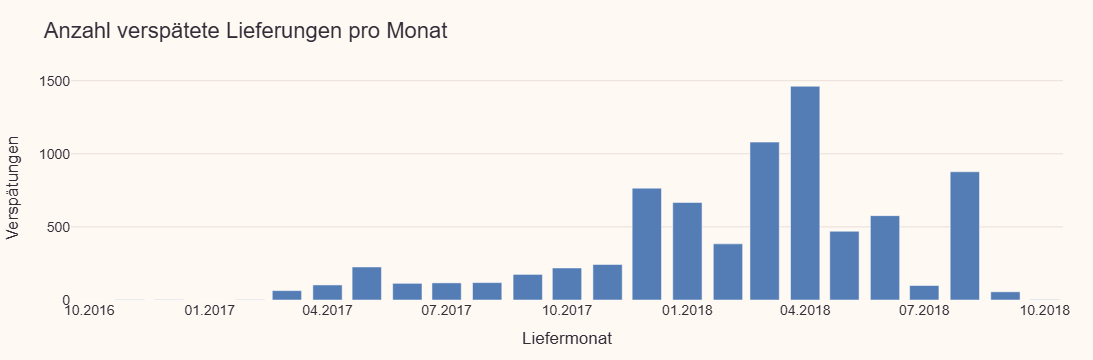

In [14]:
analyze_review_score()

#### Wie sind schlechte Bewertungen verteilt?
- Es gab drei Höhepunkte
    - 20.12.2017 mit 102 schlechte Bewertungen und 56 Verspätungen (relativ hoch)
    - 23.03.2018 mit 86 schlechte Bewertungen und 89 Verspätungen (hoch)
    - 20.05.2018 mit 88 schlechte Bewertungen und nur 2 Verspätungen.

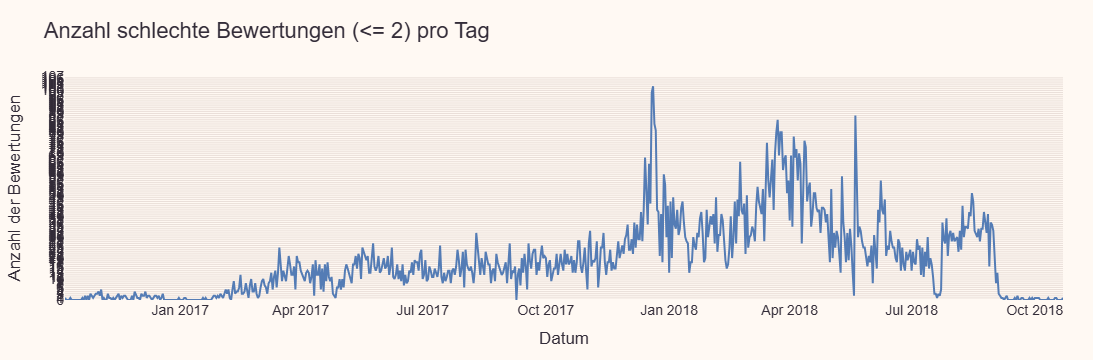

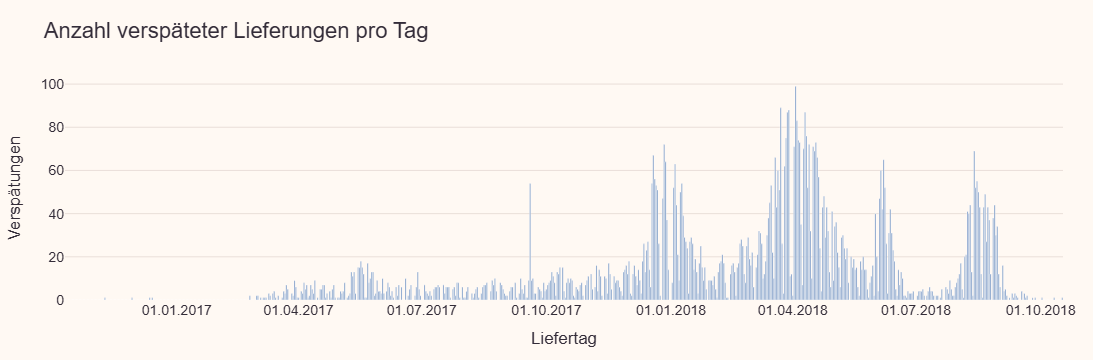

In [15]:
analyze_bad_reviews()

### Wie ist der Zusammenhang zwischen Bewertung und andere Variablen?
#### Wie hängen Bewertungen und Lieferqualität zusammen?
- Mit Abstand sind die meisten Bewertungen gleich 5 obwohl die Lieferdauer deutlich verschieden sind.
- Mit deutlichen Abstand ist die zweithöchste Bewertung die 4. Die restlichen Bewertungen sind von der Anzahl her deutlich geringer als die mit
4 oder 5 bewertet worden sind.
- Die Bewertung von Lieferzeiten über 21 Tage hat den Höhepunkt bei Bewertung 1, dann erst kommt die mit Bewertung 5.
- Die Anzahl der Verspätungen hat den höchsten Wert bei 1. Überraschenderweise kommt dann die mit Bewertung 5. Viele Kunden tolerieren Verspätungen.

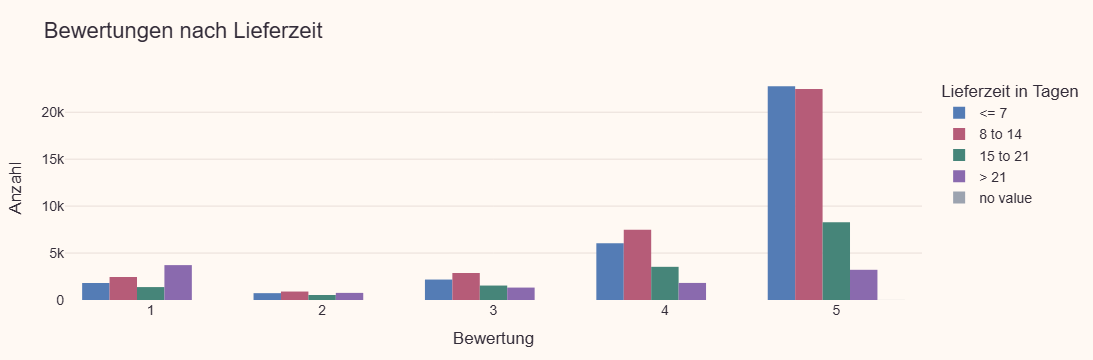

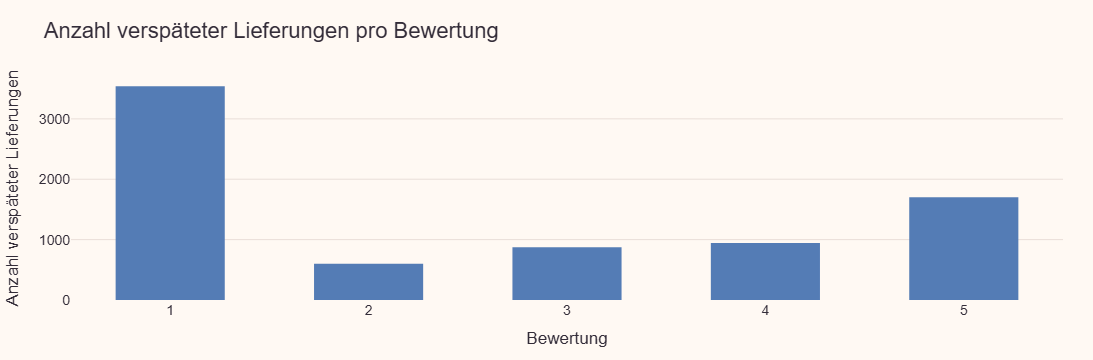

In [16]:
connection_between_delivery_quality_and_reviews()

#### Wie hängen Gesamtkosten und Bewertung zusammen?
- Der Median liegt bei allen Bewertungswerte zwischen 82.99 und 99
- Die Spearman-Korrelation beträgt -0.029, dass heißt, dass es praktisch keinen Zusammenhang zwischen Gesamtkosten und Bewertung gibt.

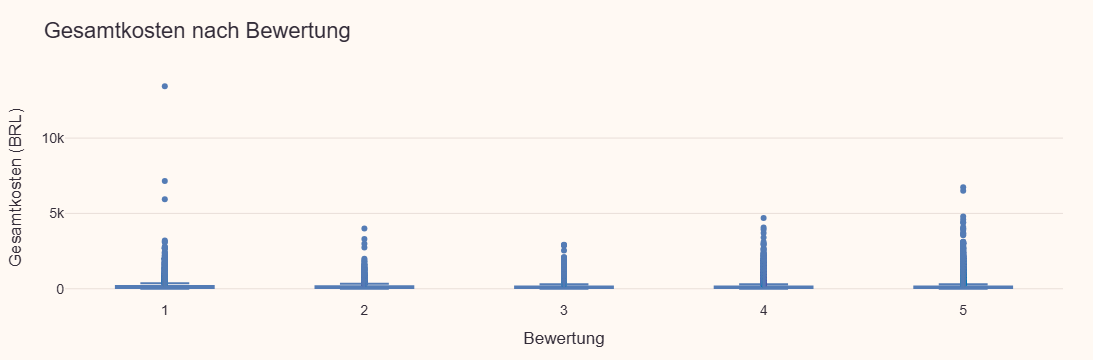

Spearman-Korrelation: -0.029


In [17]:
connection_betweeen_review_score_and_total_value()

## Data Story für Logistikleitung
### Welcher Verkäufer hat den höchsten Umsatz?
- Der höchste Wert liegt bei 247007.1 BRL.
- Die höchsten 4 liegen bei mindestens 230797 BRL.
- Danach nehmen die Umsätze kontinuierlich ab.
- relogios_presentes, cama_mesa_banho, moveis_decoracao, cool_stuff sind bei einigen Verkäufern die stärkste Produktkategorie.

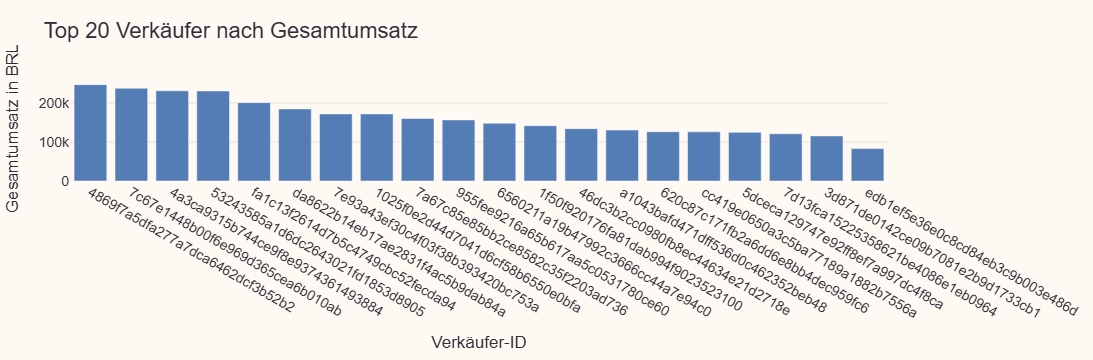

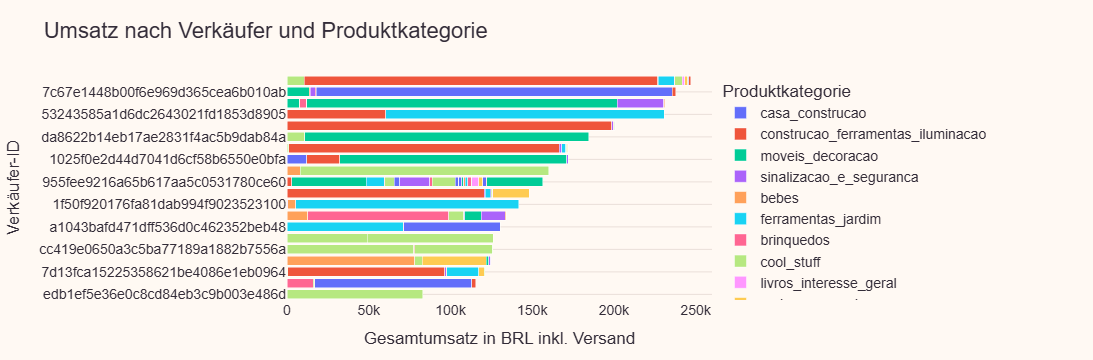

In [18]:
analyze_sales_volume_from_sellers()

### Welcher Staat von den Verkäufern hat den höchsten Umsatz?
- Mit Abstand hat der Staat Sao Paulo den höchsten Umsatz
- Dann kommen mit deutlichen Abstand Minas Gerais, Rio de Janeiro und Parana.
- Sao Paulo hat in vielen Kategorien den größten Anteil am Umsatz.

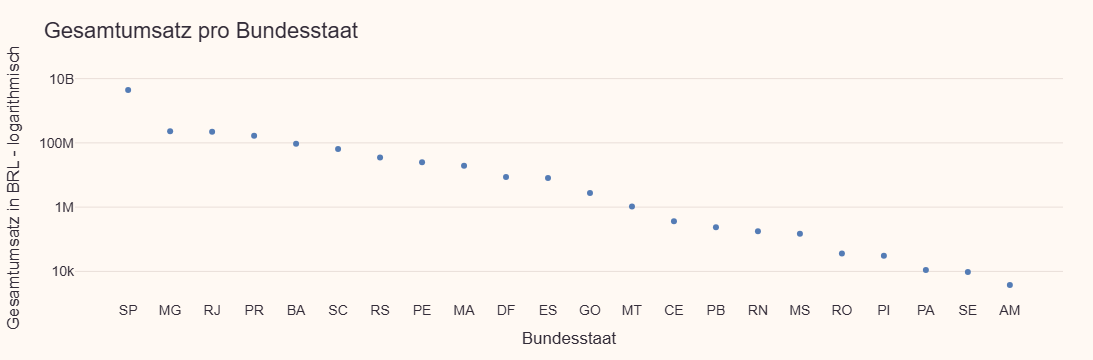

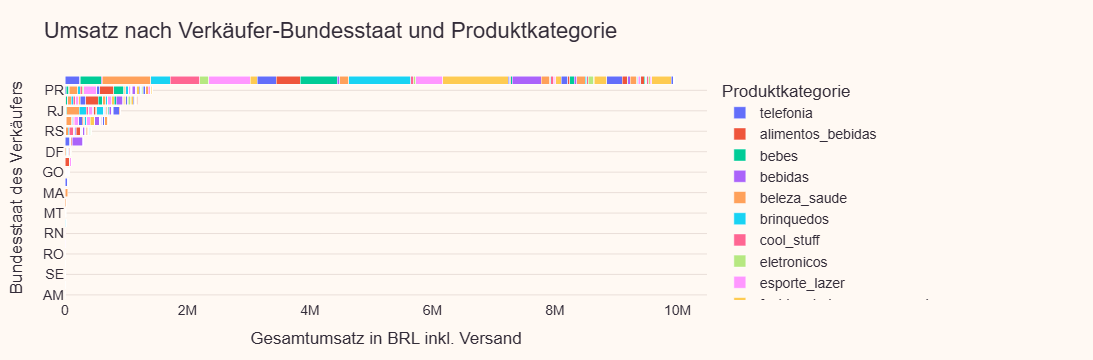

In [19]:
analyze_sales_volume_per_state()

### Wie ist der Gesamtumsatz für die Top 20 Produkte?
- Das Produkt mit den höchsten Umsatz hat einen Wert von 67000 BRL.
- Der Gesamtumsatz nimmt pro weiteres Produkt langsam ab.
- 11 Produkte der am meisten bringenden Umsatz sind auch in den Top 20 meistbestellten Produkte drin.

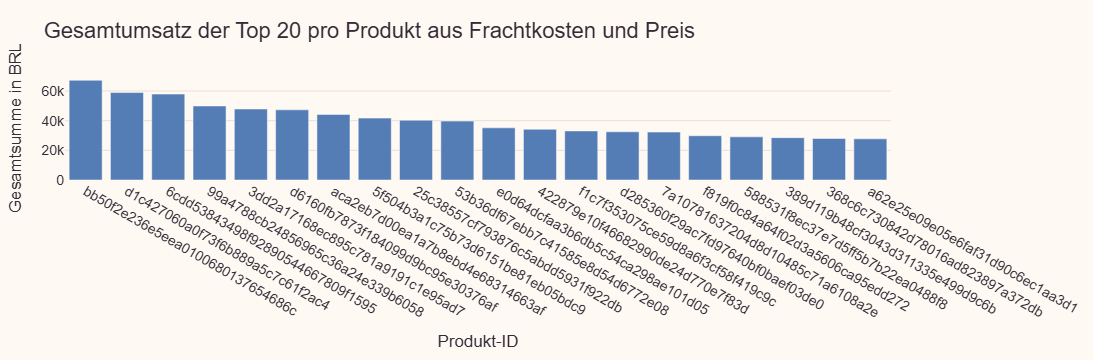

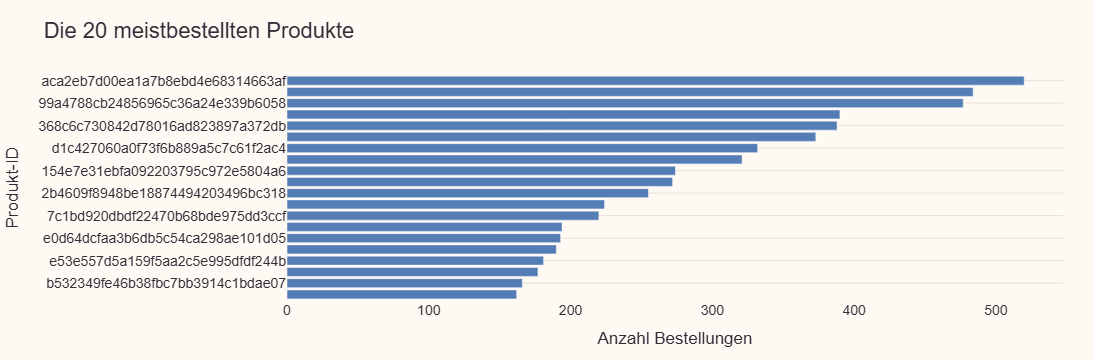

In [20]:
analyze_sales_volume_per_product_id()

### Wie ist der Gesamtumsatz pro Produktkategorie?
- Die ersten 5 Kategorien haben einen Umsatz von mehr als 1 Millionen BRL.
- Danach nimmt es kontinuierlich ab.
- Es gibt einige Produkte, die mindestens 250 Bestellungen haben. Die Produktkategorie ferramentas_jardim sticht heraus.

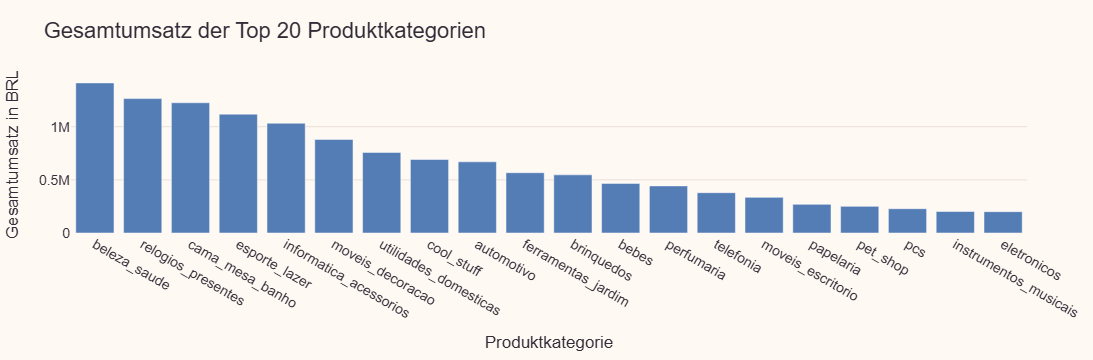

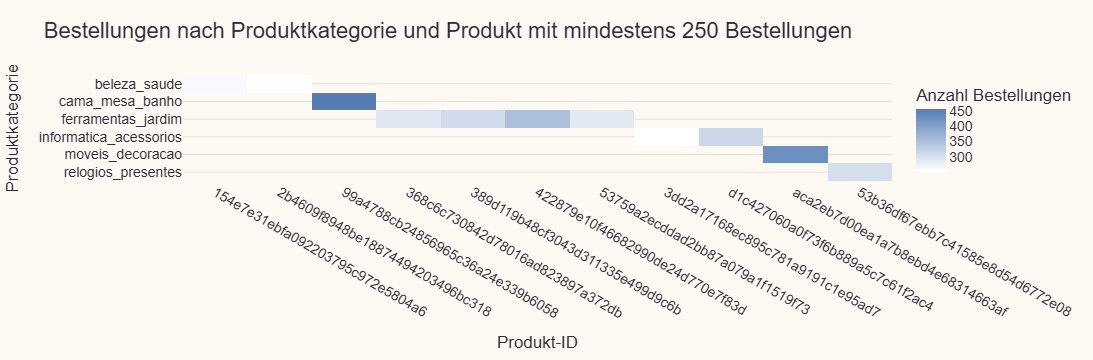

In [21]:
analyze_sales_volume_per_category()

### Wie ist der monatliche Gesamtumsatz aller Bestellungen?
- Es wurde der ausgeliefert Termin als Zeitpunkt ausgewählt, da die Bestellung dann abgeschlossen ist.
- Man sieht, dass der monatliche Gesamtumsatz im Laufe der Jahre stark gestiegen ist.
- Jedoch ist im September 2018 der Gesamtumsatz stark gesunken. Die Vermutung ist, dass noch nicht alle Daten eingetragen worden sind.

In [ ]:
draw_sales_volume_per_month()

### Welche Zusammenhänge gibt es zwischen Umsatz und anderer Variablen?
#### Wie ist der Zusammenhang zwischen Umsatz und Anzahl an veröffentlichten Fotos?
- Der Spearmankorrelationskoeffizient ist bei 0.09 -> Kein Zusammenhang
- Mit Abstand haben die meisten Produkte 1 Foto. Dann kommen 2 und 3 Fotos pro Produkt.

In [ ]:
connection_between_sales_volume_and_number_of_photos()